In [7]:
pip install pgmpy --upgrade

1

In [8]:
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling
from pgmpy.estimators import BayesianEstimator
import pandas as pd

pd.set_option('display.max_columns', None)

2


Displaying network graph...


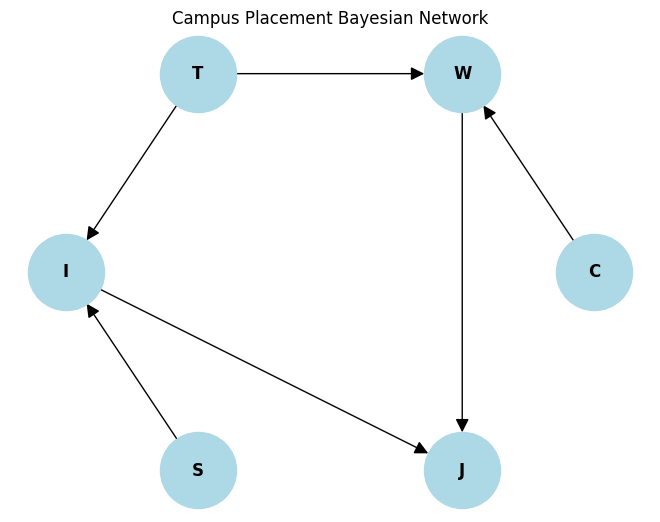

In [9]:
model_structure = [
    ('C', 'W'), ('T', 'W'),
    ('T', 'I'), ('S', 'I'),
    ('W', 'J'), ('I', 'J')
]

model = DiscreteBayesianNetwork(model_structure)

print("Displaying network graph...")
pos = nx.circular_layout(model)
nx.draw(model, pos, with_labels=True, node_size=3000, node_color='lightblue',
        font_weight='bold', arrows=True, arrowsize=20)
plt.title("Campus Placement Bayesian Network")
plt.show()

3

In [10]:
cpd_c = TabularCPD(variable='C', variable_card=3,
                   values=[[0.2], [0.5], [0.3]],
                   state_names={'C': ['Low', 'Medium', 'High']})

cpd_t = TabularCPD(variable='T', variable_card=2,
                   values=[[0.4], [0.6]],
                   state_names={'T': ['Weak', 'Strong']})

cpd_s = TabularCPD(variable='S', variable_card=2,
                   values=[[0.5], [0.5]],
                   state_names={'S': ['Weak', 'Strong']})

cpd_w = TabularCPD(variable='W', variable_card=2,
                   values=[[0.8, 0.6, 0.3, 0.4, 0.2, 0.1],
                           [0.2, 0.4, 0.7, 0.6, 0.8, 0.9]],
                   evidence=['C', 'T'], evidence_card=[3, 2],
                   state_names={'W': ['Fail', 'Pass'],
                                'C': ['Low', 'Medium', 'High'],
                                'T': ['Weak', 'Strong']})

cpd_i = TabularCPD(variable='I', variable_card=2,
                   values=[[0.7, 0.4, 0.3, 0.1],
                           [0.3, 0.6, 0.7, 0.9]],
                   evidence=['T', 'S'], evidence_card=[2, 2],
                   state_names={'I': ['Fail', 'Pass'],
                                'T': ['Weak', 'Strong'],
                                'S': ['Weak', 'Strong']})

cpd_j = TabularCPD(variable='J', variable_card=2,
                   values=[[0.99, 0.8, 0.6, 0.1],
                           [0.01, 0.2, 0.4, 0.9]],
                   evidence=['W', 'I'], evidence_card=[2, 2],
                   state_names={'J': ['No', 'Yes'],
                                'W': ['Fail', 'Pass'],
                                'I': ['Fail', 'Pass']})

model.add_cpds(cpd_c, cpd_t, cpd_s, cpd_w, cpd_i, cpd_j)

if model.check_model():
    print("Model is valid and ready for inference!")
else:
    print("Model is invalid. Check CPDs.")

Model is valid and ready for inference!


4

In [11]:
inference = VariableElimination(model)

print("--- Query 1: Baseline P(J) ---")
prob_j = inference.query(variables=['J'])
print(prob_j)

print("\n--- Query 2: P(J | C='High', T='Strong') ---")
prob_j_given_c_t = inference.query(variables=['J'],
                                   evidence={'C': 'High', 'T': 'Strong'})
print(prob_j_given_c_t)

print("\n--- Query 3: P(T | J='Yes') ---")
prob_t_given_j = inference.query(variables=['T'],
                                 evidence={'J': 'Yes'})
print(prob_t_given_j)

--- Query 1: Baseline P(J) ---
+--------+----------+
| J      |   phi(J) |
+========+==========+
| J(No)  |   0.4823 |
+--------+----------+
| J(Yes) |   0.5177 |
+--------+----------+

--- Query 2: P(J | C='High', T='Strong') ---
+--------+----------+
| J      |   phi(J) |
+========+==========+
| J(No)  |   0.2638 |
+--------+----------+
| J(Yes) |   0.7362 |
+--------+----------+

--- Query 3: P(T | J='Yes') ---
+-----------+----------+
| T         |   phi(T) |
+===========+==========+
| T(Weak)   |   0.3316 |
+-----------+----------+
| T(Strong) |   0.6684 |
+-----------+----------+


5

In [12]:
print("--- Query 4a: P(W | J='Yes') ---")
prob_w_given_j = inference.query(variables=['W'], evidence={'J': 'Yes'})
print(prob_w_given_j)

print("\n--- Query 4b: P(W | J='Yes', I='Pass') ---")
prob_w_given_j_i = inference.query(variables=['W'], evidence={'J': 'Yes', 'I': 'Pass'})
print(prob_w_given_j_i)


print("\n--- Explaining Away Analysis ---")
w_pass_j_yes = prob_w_given_j.get_value(W='Pass')
w_pass_j_yes_i_pass = prob_w_given_j_i.get_value(W='Pass')

print(f"P(W='Pass' | J='Yes') = {w_pass_j_yes:.4f}")
print(f"P(W='Pass' | J='Yes', I='Pass') = {w_pass_j_yes_i_pass:.4f}")
print("\nObservation: The probability of passing the written test decreased after we knew the student also passed the interview.")
print("Reason: This is 'explaining away'. The evidence 'I=Pass' provides a strong reason for the job offer, making the other potential cause ('W=Pass') less necessary to explain the outcome.")

--- Query 4a: P(W | J='Yes') ---
+---------+----------+
| W       |   phi(W) |
+=========+==========+
| W(Fail) |   0.0930 |
+---------+----------+
| W(Pass) |   0.9070 |
+---------+----------+

--- Query 4b: P(W | J='Yes', I='Pass') ---
+---------+----------+
| W       |   phi(W) |
+=========+==========+
| W(Fail) |   0.1092 |
+---------+----------+
| W(Pass) |   0.8908 |
+---------+----------+

--- Explaining Away Analysis ---
P(W='Pass' | J='Yes') = 0.9070
P(W='Pass' | J='Yes', I='Pass') = 0.8908

Observation: The probability of passing the written test decreased after we knew the student also passed the interview.
Reason: This is 'explaining away'. The evidence 'I=Pass' provides a strong reason for the job offer, making the other potential cause ('W=Pass') less necessary to explain the outcome.


6

In [13]:
print("--- Starting Parameter Learning ---")

sampler = BayesianModelSampling(model)
data = sampler.forward_sample(size=20000)
print(f"\nGenerated {len(data)} samples. Here's the head of the data:")
print(data.head())

model_learned = DiscreteBayesianNetwork(model_structure)

model_learned.fit(data, estimator=BayesianEstimator, prior_type="BDeu")
print("\nModel parameters have been learned from the data.")

print("\n--- Original CPD P(J | W, I) ---")
print(model.get_cpds('J'))

print("\n--- Learned CPD P(J | W, I) from 20,000 samples ---")
learned_cpd_j = model_learned.get_cpds('J')
print(learned_cpd_j)

print("\nAnalysis: As you can see, the learned probabilities are very close to the original ones.")

--- Starting Parameter Learning ---


  0%|          | 0/6 [00:00<?, ?it/s]


Generated 20000 samples. Here's the head of the data:
        C     W       T     I       S    J
0  Medium  Fail    Weak  Pass    Weak   No
1  Medium  Fail  Strong  Pass    Weak   No
2    High  Pass    Weak  Fail    Weak  Yes
3  Medium  Fail    Weak  Fail  Strong   No
4    High  Pass  Strong  Pass  Strong  Yes

Model parameters have been learned from the data.

--- Original CPD P(J | W, I) ---
+--------+---------+---------+---------+---------+
| W      | W(Fail) | W(Fail) | W(Pass) | W(Pass) |
+--------+---------+---------+---------+---------+
| I      | I(Fail) | I(Pass) | I(Fail) | I(Pass) |
+--------+---------+---------+---------+---------+
| J(No)  | 0.99    | 0.8     | 0.6     | 0.1     |
+--------+---------+---------+---------+---------+
| J(Yes) | 0.01    | 0.2     | 0.4     | 0.9     |
+--------+---------+---------+---------+---------+

--- Learned CPD P(J | W, I) from 20,000 samples ---
+--------+----------------------+-----+---------------------+
| I      | I(Fail)          